# Geodata Visualization with GeoPandas

In this session you will turn tables of numbers into **maps** and learn why *where* something is changes how you
have to analyse it. We work with one small, free dataset all the way through: **the countries and big cities of the world**.

**Datasets** (all small, downloaded automatically on first run and cached in `data/`)

| Layer | Source | What we use it for |
|---|---|---|
| Countries, 1:110m | [Natural Earth](https://www.naturalearthdata.com/) (public domain) | polygons + population, GDP, income group |
| Populated places, 1:110m | Natural Earth (public domain) | points: capitals and large cities |
| Population 1960–2025 | World Bank series repackaged in the [`datasets/population`](https://github.com/datasets/population) repo | a plain CSV we must *join* to the polygons |


## Part 0 — Setup

In [1]:
# Run once if a package is missing (fresh Colab, new virtual environment...):
# !pip install geopandas mapclassify folium matplotlib

In [2]:
import urllib.request
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from shapely.geometry import Point, box

warnings.filterwarnings("ignore", message="Numba not installed")      # harmless speed hint from mapclassify
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold"}) # For consistency
print("geopandas", gpd.__version__)

geopandas 1.2.0


In [3]:
DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

NE_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/{name}.geojson"
POP_URL = "https://raw.githubusercontent.com/datasets/population/main/data/population.csv"


def fetch(url, path):
    """Download `url` to `path` once; reuse the local copy afterwards."""
    if not path.exists():
        print(f"Downloading {path.name} ...")
        urllib.request.urlretrieve(url, path)
    return path


def load_natural_earth(name):
    return gpd.read_file(fetch(NE_URL.format(name=name), DATA_DIR / f"{name}.geojson"))


def load_population():
    return pd.read_csv(fetch(POP_URL, DATA_DIR / "population.csv"))

## Part 1 — Anatomy of a GeoDataFrame

A **`GeoDataFrame`** is a pandas `DataFrame` with two extras:

- a special **geometry column** holding shapes (points, lines, polygons) — *what* and *where*;
- a **CRS** (coordinate reference system) saying how the numbers in those shapes map to places on Earth.

Everything you know from pandas (filtering, `groupby`, `merge`, ...) still works.

In [4]:
countries_raw = load_natural_earth("ne_110m_admin_0_countries")
print(type(countries_raw).__name__, countries_raw.shape)
print("CRS:", countries_raw.crs)

GeoDataFrame (177, 169)
CRS: EPSG:4326


The raw file has 169 columns. We keep a handful, give them short names, and drop Antarctica and the open-ocean feature (they distort world maps).

In [5]:
keep = {
    "NAME": "name", "ADM0_A3": "iso3", "CONTINENT": "continent",
    "INCOME_GRP": "income_group", "POP_EST": "population", "GDP_MD": "gdp_musd",
}
countries = (
    countries_raw[~countries_raw["CONTINENT"].isin(["Antarctica", "Seven seas (open ocean)"])]
    [list(keep) + ["geometry"]]
    .rename(columns=keep)
    .reset_index(drop=True)
)
# GDP is in millions of USD in the source -> convert to USD per person
countries["gdp_per_capita"] = countries["gdp_musd"] * 1e6 / countries["population"]
countries.head()

,name,iso3,continent,income_group,population,gdp_musd,geometry,gdp_per_capita
0,Fiji,FJI,Oceania,4. Lower middle income,889953.0,5496,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ...",6175.607026
1,Tanzania,TZA,Africa,5. Low income,58005463.0,63177,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3...",1089.156033
2,W. Sahara,SAH,Africa,5. Low income,603253.0,907,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948...",1503.515109
3,Canada,CAN,North America,1. High income: OECD,37589262.0,1736425,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025...",46194.708478
4,United States of America,USA,North America,1. High income: OECD,328239523.0,21433226,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312...",65297.517508


Each row is a country; the last column holds its shape. What kinds of shapes are there?

Polygon         147
MultiPolygon     28
Name: count, dtype: int64


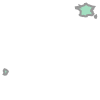

In [14]:
print(countries.geometry.geom_type.value_counts())
countries.loc[countries["name"] == "France", "geometry"].iloc[0]   # a notebook draws shapely objects directly

Notice that France is drawn as **several pieces** — a `MultiPolygon` — because it includes overseas territory
(French Guiana in South America). A country with islands or exclaves is *one row* but *many polygons*.

The **bounds** tell you where the data lives: `(minx, miny, maxx, maxy)`. Here that is (longitude, latitude).

In [7]:
print(countries.total_bounds)           # whole layer
countries.geometry.bounds.head(3)       # one row per feature

[-180.       -55.61183  180.        83.64513]


,minx,miny,maxx,maxy
0,-180.000000,-18.287990,180.000000,-16.020882
1,29.339998,-11.720938,40.316590,-0.950000
2,-17.063423,20.999752,-8.665124,27.656426


### Exercise 1 — Africa as a subset

Use ordinary pandas filtering on `countries`:

1. `africa`: the rows whose `continent` is `"Africa"`.
2. `n_africa`: how many countries that is.
3. `top3_population`: a **list** with the names of the three most populous African countries, biggest first.
4. Plot Africa on its own: `figsize=(6, 6)`, a neutral fill, a thin dark outline, a title, **no axes**.

*Hint: `nlargest`, `.tolist()`, `ax.set_axis_off()`.*

In [8]:
africa = ...             # TODO: filter on the 'continent' column
n_africa = ...           # TODO
top3_population = ...    # TODO: list of 3 country names

# TODO: plot Africa (neutral fill, thin dark outline, title, no axes) and keep the Axes in `ax`
ax = ...

In [9]:
# Assert
assert n_africa == 51, "n_africa should be the number of African countries in the table"
assert top3_population == ["Nigeria", "Ethiopia", "Egypt"], f"top3_population is {top3_population}"
assert africa.geometry is not None and (africa["continent"] == "Africa").all()
assert ax.get_title() != "" and not ax.axison, "Give the map a title and switch the axes off"
print("Exercise is correct")

AssertionError: n_africa should be the number of African countries in the table

## Part 2 — First maps

`GeoDataFrame.plot()` is a thin wrapper around matplotlib. It draws the geometry column and returns a matplotlib **`Axes`**,
so everything you know (`set_title`, `set_xlim`, `fig.savefig`, ...) applies.

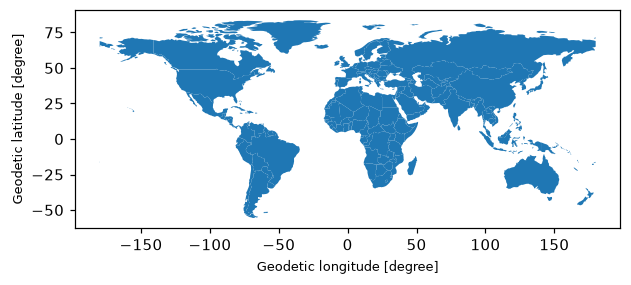

In [10]:
countries.plot();

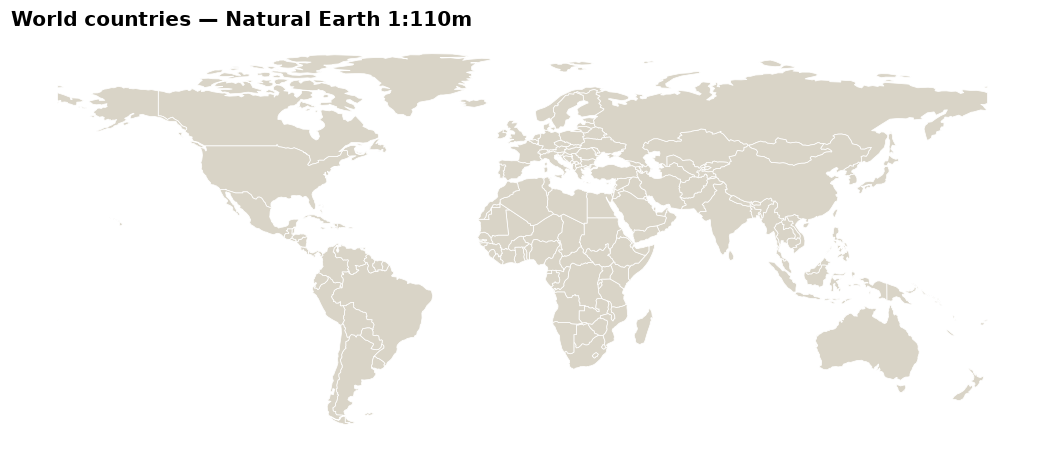

In [11]:
ax = countries.plot(figsize=(12, 6), color="#d9d4c7", edgecolor="white", linewidth=0.5)
ax.set_title("World countries — Natural Earth 1:110m", loc="left")
ax.set_axis_off()

Passing `column=` colours each shape by a value. With `categorical=True` every distinct value gets its own colour:

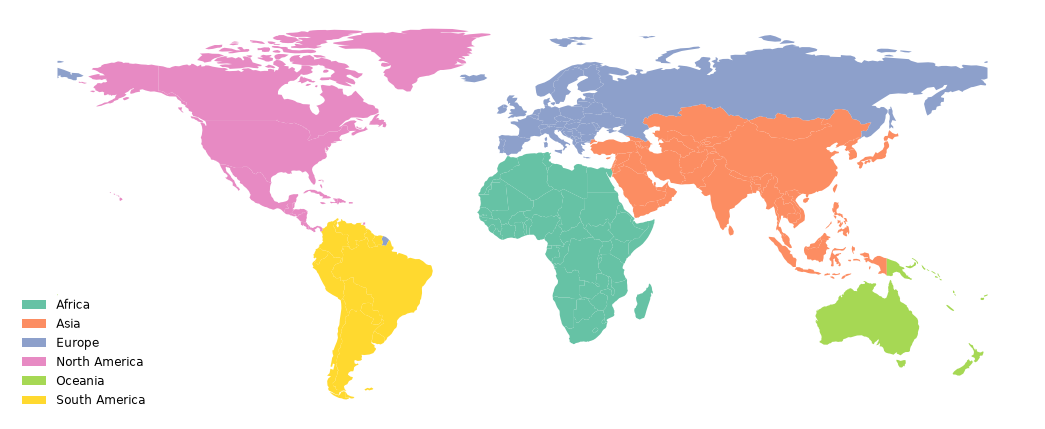

In [12]:
ax = countries.plot(
    column="continent", categorical=True, cmap="Set2", legend=True, figsize=(12, 6),
    legend_kwds={"loc": "lower left", "fontsize": 8, "frameon": False},
)
ax.set_axis_off()

### Exercise 2 — Income groups

The column `income_group` holds the World Bank income classification, **prefixed with a number** ("1. High income: OECD" … "5. Low income").

1. Draw a categorical map of `income_group` (`figsize=(12, 6)`). Choose a colormap in which **darker = richer**
   (hint: the categories are sorted alphabetically, so the *first* category gets the *first* colour of the colormap — try `"YlGnBu_r"`).
   Use thin white borders, a legend in the lower left, a left-aligned title and no axes. Keep the Axes in `ax`.
2. `income_counts`: a Series with the number of countries per income group, **sorted by group name** (so group 1 comes first).

In [ ]:
# TODO: categorical map of 'income_group' -> keep the Axes in `ax`
ax = ...

income_counts = ...   # TODO

In [ ]:
assert income_counts.sum() == len(countries), "every country belongs to one income group"
assert income_counts.index[0].startswith("1."), "sort the counts by group name"
assert ax.get_legend() is not None, "add a legend"
assert ax.get_title(loc="left") != "", "add a left-aligned title"
assert not ax.axison, "switch the axes off"
print("Exercise 2 ok")

## Part 3 — Choropleths

A **choropleth** colours areas by a numeric value. Three decisions decide whether it is honest or misleading:

1. **What you map** — use *rates* (per person, per km²), not raw totals, because big areas/populations dominate raw counts.
2. **How you classify** the values into colours.
3. **Which colours** (sequential for "low → high", diverging for "below / above a meaningful midpoint").

### 3.1 Classification matters

Population is very skewed: a few giants (China, India) and many small countries.

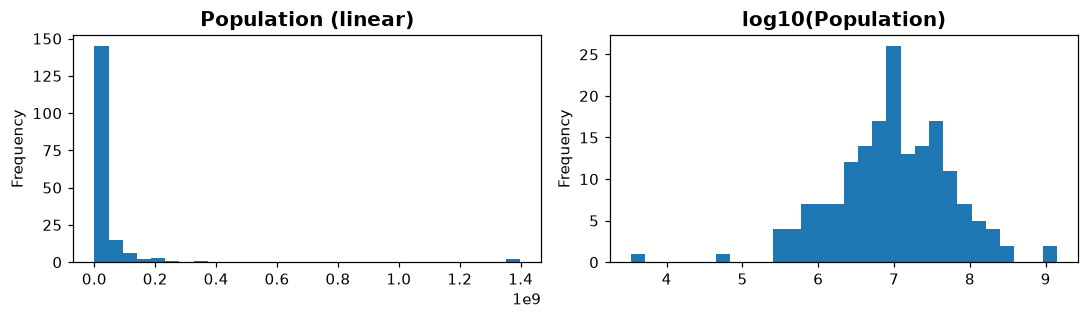

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
countries["population"].plot.hist(bins=30, ax=axes[0], title="Population (linear)")
np.log10(countries["population"]).plot.hist(bins=30, ax=axes[1], title="log10(Population)")
fig.tight_layout()

The same data, four classification schemes (they need the `mapclassify` package, which GeoPandas calls for you):

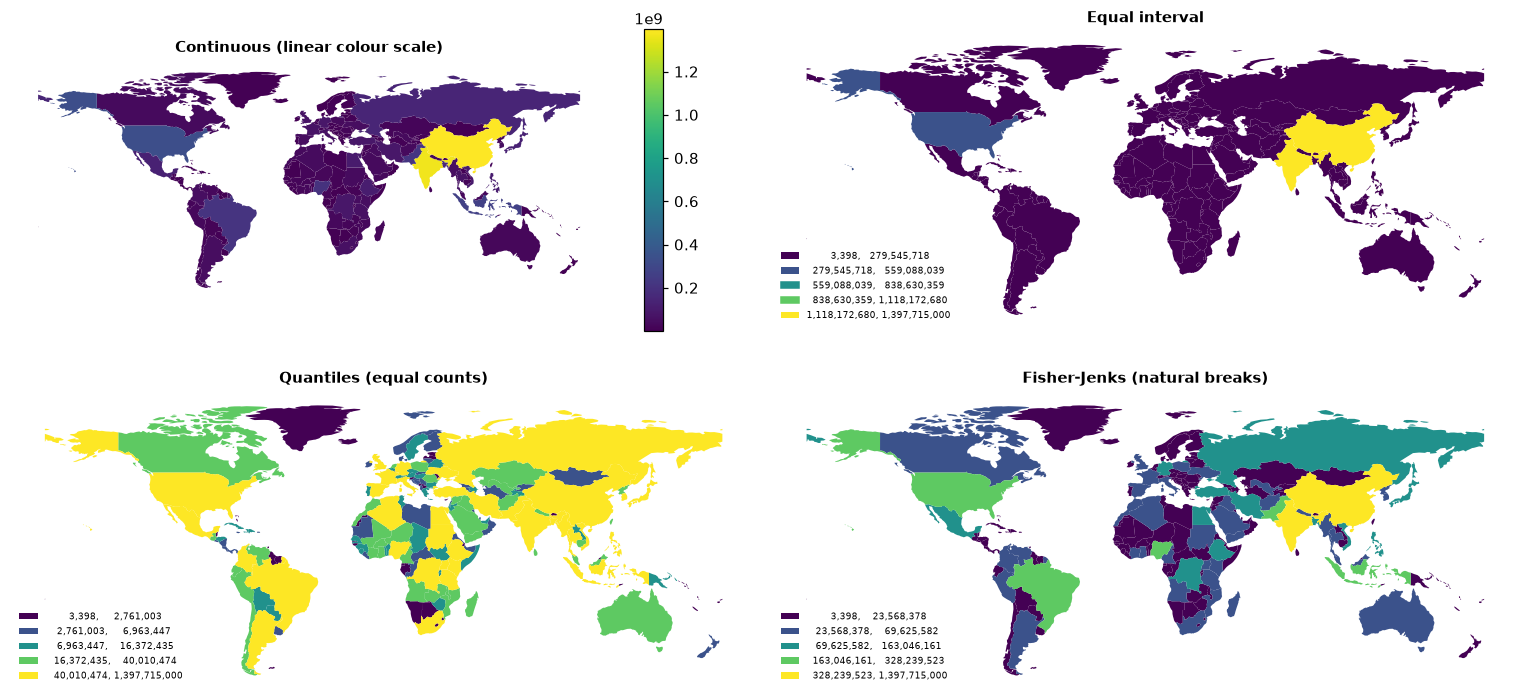

In [ ]:
schemes = {
    "Continuous (linear colour scale)": None, #smooth gradient from the smallest value to the largest
    "Equal interval": "equalinterval", #Split the range from smallest to largest into slices of equal width
    "Quantiles (equal counts)": "quantiles", #Sort the countries and put the same number in each group
    "Fisher-Jenks (natural breaks)": "fisherjenks", #looks for the gaps in the data and puts the limits there, 
    #                                               so countries in the same class are as similar as possible and classes are as different as possible
}
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, (title, scheme) in zip(axes.ravel(), schemes.items()): # Flattening 2x2 into list of 4items
    options = {} if scheme is None else {
        "scheme": scheme, "k": 5,
        "legend_kwds": {"loc": "lower left", "fontsize": 6, "fmt": "{:,.0f}", "frameon": False},
    }
    countries.plot("population", ax=ax, cmap="viridis", legend=True, **options)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
fig.tight_layout()

### 3.2 Rates vs total

GDP per person says more about living standards than total GDP, which mostly mirrors population size.
Notice `legend_kwds` — `fmt` formats the class limits and `title` labels the legend.

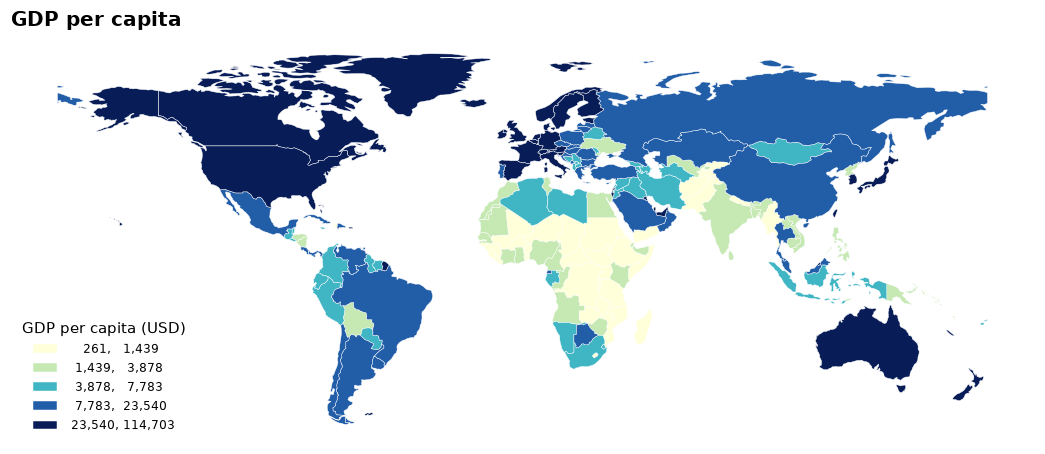

In [22]:
ax = countries.plot(
    "gdp_per_capita", scheme="quantiles", k=5, cmap="YlGnBu", # colormap - yellow, green, blue
    edgecolor="white", linewidth=0.3, figsize=(12, 6), legend=True,
    legend_kwds={"loc": "lower left", "fmt": "{:,.0f}", "title": "GDP per capita (USD)", "fontsize": 8, "frameon": False},
)
ax.set_title("GDP per capita", loc="left")
ax.set_axis_off()

### 3.3 Joining a plain table onto the geometries

Real projects rarely have everything in one file. Here the population history is a **CSV** (one row per country *and year*).
To map it we must:

1. reshape it to one row per country,
2. find a **shared key** — the 3-letter ISO country code,
3. **merge** onto the `GeoDataFrame` (the GeoDataFrame must be on the *left* so the result keeps its geometry),
4. check what **did not match**.

In [23]:
pop_hist = load_population()
pop_hist.head()

,Country Name,Country Code,Year,Value
0,Aruba,ABW,1960,54922
1,Aruba,ABW,1961,55578
2,Aruba,ABW,1962,56320
3,Aruba,ABW,1963,57002
4,Aruba,ABW,1964,57619


In [30]:
# one row per country code, one column per year
wide = pop_hist.pivot(index="Country Code", columns="Year", values="Value")
wide.head()
# which of our shapes have no match in the table?
no_match = countries.loc[~countries["iso3"].isin(wide.index), ["name", "iso3"]]
no_match

,name,iso3
2,W. Sahara,SAH
20,Falkland Is.,FLK
78,Palestine,PSX
139,Taiwan,TWN
158,N. Cyprus,CYN
165,Somaliland,SOL
172,Kosovo,KOS
174,S. Sudan,SDS


Eight shapes do not match. If you checked and compared both tables, you would see that three of those are only **code differences** between providers (South Sudan, Palestine, Kosovo) and can be fixed; the other five (Taiwan, Western Sahara, Falkland Islands, Northern Cyprus, Somaliland) simply **have no data** in the World Bank table.

In [25]:
CODE_FIXES = {"SDS": "SSD", "PSX": "PSE", "KOS": "XKX"}      # Natural Earth code -> World Bank code
countries["wb_code"] = countries["iso3"].replace(CODE_FIXES)

countries = countries.merge(
    wide[[2000]].rename(columns={2000: "pop_2000"}), # Taking year 2000 as an example
    left_on="wb_code", right_index=True, how="left", #keep every row of countries, even if it finds no match
    validate="one_to_one",	#stop with an error if any key appears more than once on either side
)
print(type(countries).__name__, "| missing pop_2000:", countries["pop_2000"].isna().sum())

GeoDataFrame | missing pop_2000: 5


Missing values must be shown as **"no data"**, never as zero. `missing_kwds` controls how they are drawn:

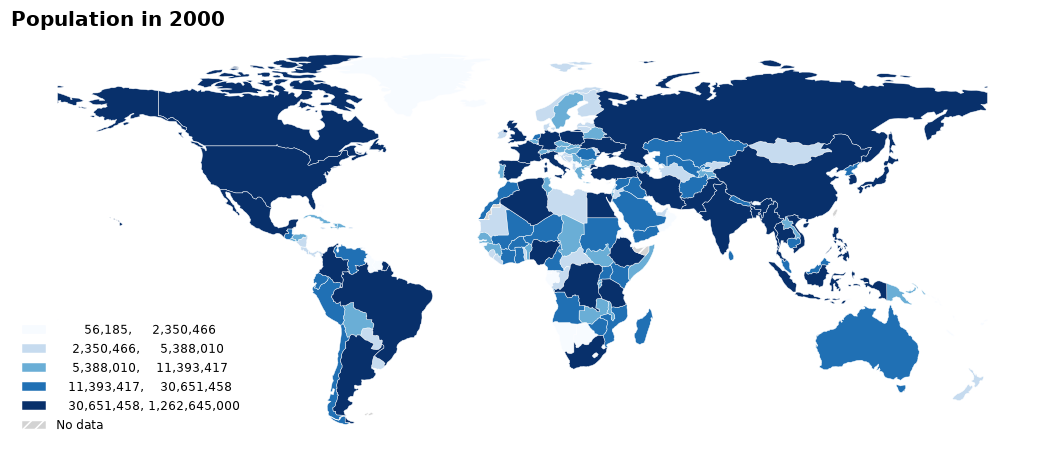

In [31]:
ax = countries.plot(
    "pop_2000", scheme="quantiles", k=5, cmap="Blues", figsize=(12, 6),
    edgecolor="white", linewidth=0.3, legend=True,
    legend_kwds={"loc": "lower left", "fmt": "{:,.0f}", "fontsize": 8, "frameon": False},
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "hatch": "///", "label": "No data"},
)
ax.set_title("Population in 2000", loc="left")
ax.set_axis_off()

### Exercise 3 — Where is the population growing?

Using the `wide` table and the `CODE_FIXES` join from above:

1. Add a column `pop_2024` to `countries` (same recipe as `pop_2000`, but for year **2024**).
2. Add a column `growth_pct` = percentage change in population from 2000 to 2024.
3. `n_missing`: the number of countries for which `growth_pct` is missing.
4. Draw a **diverging** map of `growth_pct` (`figsize=(12, 6)`): `cmap="RdBu"`, centred on **0** with
   `TwoSlopeNorm(vmin=-50, vcenter=0, vmax=200)` so that red = shrinking and blue = growing.
   Draw missing countries light grey with hatching, add a colourbar label, a title and switch the axes off. Keep the Axes in `ax`.

*Hint: for a continuous scale pass `norm=` to `plot()`, and `legend_kwds={"label": ..., "shrink": 0.6}` for the colourbar.*

In [ ]:
# 1. + 2. new columns on `countries`
...

n_missing = ...     # TODO

# 4. diverging map -> keep the Axes in `ax`
ax = ...

In [ ]:
assert "pop_2024" in countries.columns and "growth_pct" in countries.columns, "add both columns to `countries`"
assert n_missing == 5, f"expected 5 countries without data, got {n_missing}"
fra = countries.set_index("iso3").loc["FRA", "growth_pct"]
assert 11 < fra < 14, f"France's growth should be about +12.5 %, got {fra:.1f}"
assert isinstance(countries, gpd.GeoDataFrame), "`countries` must stay a GeoDataFrame"
assert ax.get_title(loc="left") != "" and not ax.axison
print("Exercise correct")

## Part 4 — Coordinate reference systems (CRS)

The Earth is (roughly) a sphere; a screen is flat. A **CRS** fixes how positions are written as numbers.

- **Geographic CRS** (e.g. `EPSG:4326`, WGS 84): coordinates are *degrees* of longitude/latitude. Good for storing and exchanging.
- **Projected CRS**: coordinates are *metres* on a flat plane. Every projection must distort **something** — shape, area, distance or direction.

Our layer is stored in `EPSG:4326`. Use `.to_crs()` to **re-project**.

In [32]:
print(countries.crs.name, "| geographic:", countries.crs.is_geographic)

WGS 84 | geographic: True


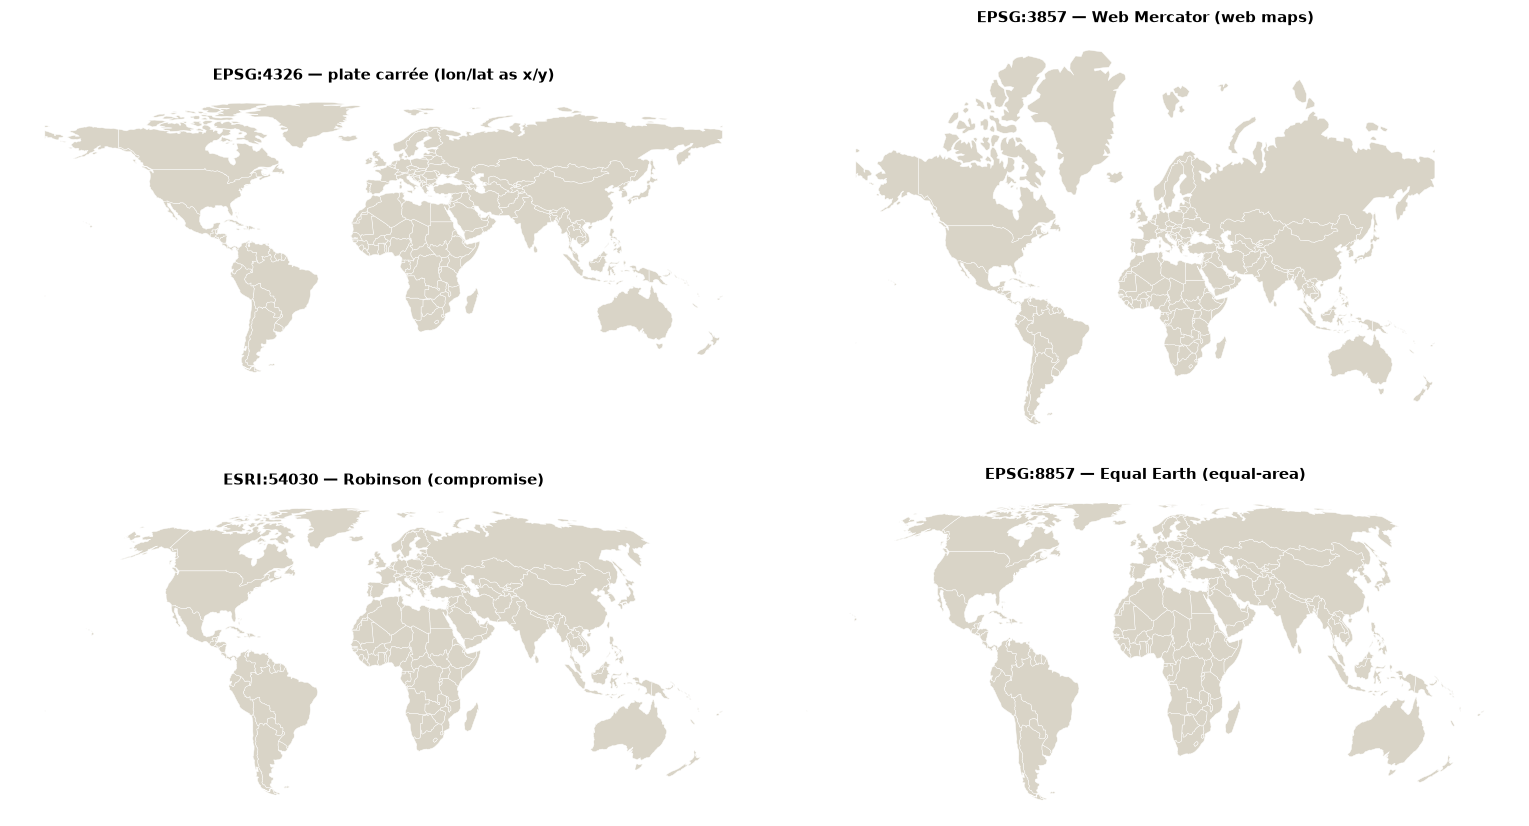

In [33]:
crs_options = {
    "EPSG:4326 — plate carrée (lon/lat as x/y)": "EPSG:4326",
    "EPSG:3857 — Web Mercator (web maps)": "EPSG:3857",
    "ESRI:54030 — Robinson (compromise)": "ESRI:54030",
    "EPSG:8857 — Equal Earth (equal-area)": "EPSG:8857",
}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (title, crs) in zip(axes.ravel(), crs_options.items()):
    countries.to_crs(crs).plot(ax=ax, color="#d9d4c7", edgecolor="white", linewidth=0.3)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
fig.tight_layout()

### Measuring areas: never in degrees

In [37]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    countries.geometry.area            # area in "square degrees"
print(caught[0].message)

Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.



In [38]:
warnings.filterwarnings("ignore", message=".*geographic CRS.*")      # we have seen it, now silence it


def greenland_vs_africa(crs):
    g = countries.to_crs(crs)
    return g.loc[g["name"] == "Greenland"].area.iloc[0] / g.loc[g["continent"] == "Africa"].area.sum()


pd.Series({label: greenland_vs_africa(crs) for label, crs in crs_options.items()},
          name="Greenland's area as % of Africa's").map("{:.0%}".format)

EPSG:4326 — plate carrée (lon/lat as x/y)     26%
EPSG:3857 — Web Mercator (web maps)          108%
ESRI:54030 — Robinson (compromise)            14%
EPSG:8857 — Equal Earth (equal-area)           7%
Name: Greenland's area as % of Africa's, dtype: str

In reality Greenland is about **7 %** of Africa's area. Only the equal-area projection gets that right; Web Mercator makes it look about as large as a whole continent.

In [39]:
# the right way: project to an equal-area CRS, then measure (m² -> km²)
countries["area_km2"] = countries.to_crs("EPSG:8857").area / 1e6
countries.set_index("name").loc[["Greenland", "France", "Russia"], "area_km2"].round(0)

name
Greenland     2206879.0
France         644863.0
Russia       17017039.0
Name: area_km2, dtype: float64

### Exercise 4 — Population density

Using the `area_km2` column computed above:

1. Add a column `density` = people per km² (`population / area_km2`).
2. `top5_density`: a list of the names of the **five most densely populated** countries, densest first.
3. Draw a choropleth of `density` in the **Equal Earth** projection with **hand-chosen class limits** that make sense for people —
   `scheme="userdefined"` with `classification_kwds={"bins": [10, 25, 50, 100, 250, 500, <max density>]}`.
   Use `cmap="OrRd"`, `figsize=(12, 6)`, a legend (lower left), a left-aligned title, no axes. Keep the Axes in `ax`.

*Hint: reproject with `countries.to_crs("EPSG:8857")` **before** plotting; the new `density` column is carried along.*

In [ ]:
countries["density"] = ...     # TODO

top5_density = ...             # TODO: list of 5 names

# TODO: choropleth in Equal Earth with user-defined bins -> keep the Axes in `ax`
ax = ...

In [ ]:
assert "density" in countries.columns, "add the `density` column"
assert top5_density == ["Bangladesh", "Palestine", "Taiwan", "Lebanon", "Rwanda"], f"top5_density is {top5_density}"
assert 95 < countries.set_index("name").loc["France", "density"] < 115, "France is about 104 people/km² here"
assert ax.get_legend() is not None and not ax.axison
print("Exercise correct")

### Exercise 5 — A map of Europe in a European projection

World projections are poor for a single region. Make a map of Europe in **ETRS89-LAEA (`EPSG:3035`)**, the official European equal-area CRS:

1. `europe`: the countries **clipped** to the lon/lat window `(-25, 34, 45, 72)` (min lon, min lat, max lon, max lat),
   then **re-projected** to `EPSG:3035`. *(Clip first, then reproject — otherwise Russia, France's overseas pieces and Greenland spoil the extent.)*
2. Plot `gdp_per_capita` for `europe` with quantiles (`k=5`), `cmap="YlGnBu"`, thin white outlines, legend, left-aligned title, no axes. Keep the Axes in `ax`.

*Hint: `countries.clip((minx, miny, maxx, maxy))`.*

In [ ]:
europe = ...    # TODO: clip, then to_crs

# TODO: quantile choropleth of GDP per capita -> keep the Axes in `ax`
ax = ...

In [ ]:
assert europe.crs.to_epsg() == 3035, "re-project `europe` to EPSG:3035"
assert 45 <= len(europe) <= 60, "did you clip to the window?"
assert europe.total_bounds[0] > 2_000_000, "clip BEFORE reprojecting so that overseas territories are removed"
assert ax.get_legend() is not None and not ax.axison and ax.get_title(loc="left") != ""
print("Exercise correct")

## Part 5 — Points and layers

Our second layer holds **populated places** (points). To draw several layers on one map, **plot each on the same `Axes`** by passing `ax=`.
The layer plotted last ends up on top.

In [40]:
cities = (
    load_natural_earth("ne_110m_populated_places")
    [["NAME", "ADM0NAME", "ADM0_A3", "FEATURECLA", "POP_MAX", "geometry"]]
    .rename(columns={"NAME": "city", "ADM0NAME": "country", "ADM0_A3": "iso3",
                     "FEATURECLA": "feature_class", "POP_MAX": "pop_max"})
)
big_cities = cities[cities["pop_max"] >= 5_000_000]        # the "5 million+" cities, used from here on
print(len(cities), "places,", len(big_cities), "with at least 5 million inhabitants")
big_cities.sort_values("pop_max", ascending=False).head()

243 places, 38 with at least 5 million inhabitants


,city,country,iso3,feature_class,pop_max,geometry
233,Tokyo,Japan,JPN,Admin-0 capital,35676000,POINT (139.74946 35.68696)
218,New York,United States of America,USA,Populated place,19040000,POINT (-73.99572 40.72156)
224,Mexico City,Mexico,MEX,Admin-0 capital,19028000,POINT (-99.13293 19.44439)
234,Mumbai,India,IND,Admin-1 capital,18978000,POINT (72.87584 19.06841)
239,São Paulo,Brazil,BRA,Admin-1 capital,18845000,POINT (-46.62697 -23.55673)


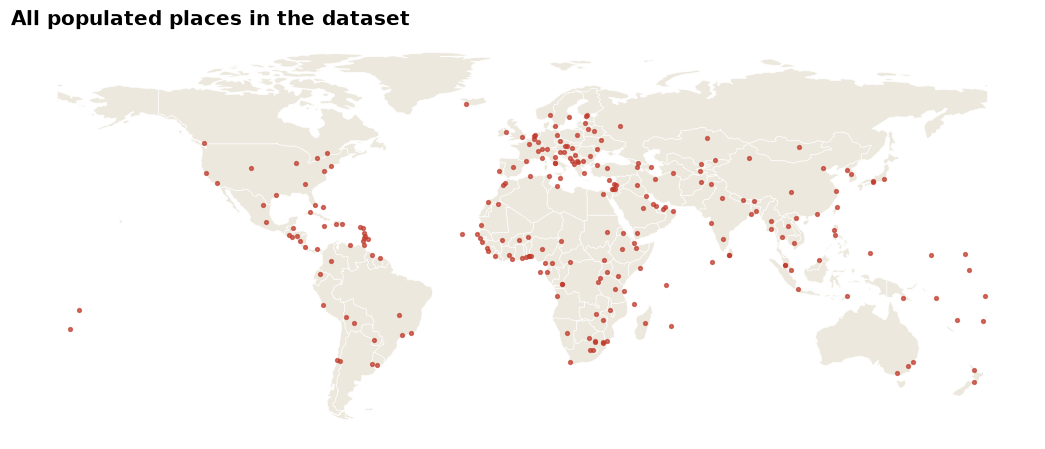

In [41]:
fig, ax = plt.subplots(figsize=(12, 6))
countries.plot(ax=ax, color="#ece8dd", edgecolor="white", linewidth=0.4)        # layer 1: polygons
cities.plot(ax=ax, color="#c0392b", markersize=6, alpha=0.7)                    # layer 2: points on top; markersize=point size, alpha=opacity
ax.set_title("All populated places in the dataset", loc="left")
ax.set_axis_off()

**Proportional symbols**: `markersize` is in points² — i.e. an *area*. To make the *area* of the circle proportional to the population,
make `markersize` proportional to the population (not its square root).

### Exercise 6 — Bubble map of big cities

Draw the cities in `big_cities` on top of a light grey world map (`figsize=(13, 6.5)`):

1. Circle **area proportional to `pop_max`** (about 1 point² per 40 000 inhabitants works well), semi-transparent red fill, black thin outline (`edgecolor`, `linewidth`).
2. `top10`: the 10 largest cities as a DataFrame sorted by `pop_max` (largest first), and **label** them on the map with `ax.annotate` (font size 7, small offset).
3. A left-aligned title and no axes. Keep the Axes in `ax`.

*Hint: a point's coordinates are `geom.x` and `geom.y`; `ax.annotate(text, (x, y), xytext=(4, 4), textcoords="offset points")`.*

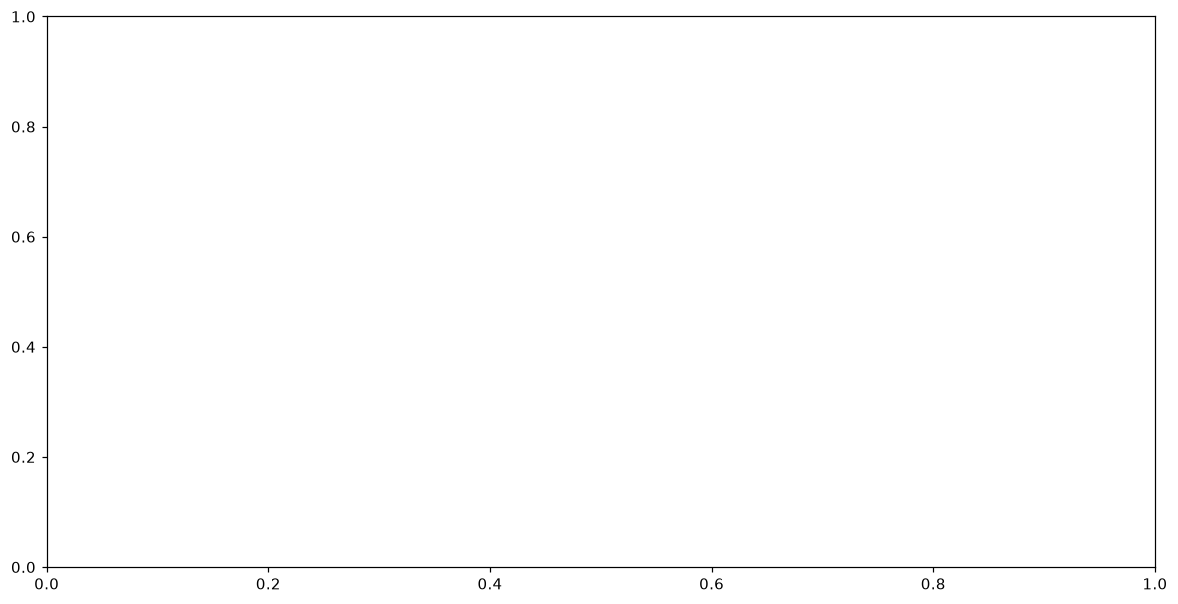

In [42]:
top10 = ...     # TODO: DataFrame of the 10 largest cities

fig, ax = plt.subplots(figsize=(13, 6.5))
# TODO: base layer, proportional-symbol layer, labels, title, no axes

In [ ]:
assert len(top10) == 10 and top10["pop_max"].is_monotonic_decreasing, "top10 must be sorted, largest first"
assert len(ax.collections) >= 2, "plot the world AND the cities on the same Axes"
assert len(ax.texts) >= 10, "label the 10 largest cities with ax.annotate"
assert not ax.axison and ax.get_title(loc="left") != ""
print("Exercise correct")

## Part 6 — Spatial operations

Three operations that you will use constantly:

| Operation | Question it answers | Tool |
|---|---|---|
| **Spatial join** | *Which polygon contains each point?* | `gpd.sjoin(points, polygons, predicate="within")` |
| **Dissolve** | *Merge polygons that share an attribute* (a spatial `groupby`) | `gdf.dissolve(by=..., aggfunc=...)` |
| **Buffer / distance** | *What is within X metres of here?* | `geom.buffer(metres)` in a **projected** CRS |

### 6.1 Spatial join

In [ ]:
polys = countries[["name", "continent", "geometry"]].rename(columns={"name": "poly_country", "continent": "poly_continent"})
joined = gpd.sjoin(cities, polys, how="left", predicate="within")

unmatched = joined["poly_country"].isna()
print(f"{unmatched.sum()} of {len(joined)} cities are not inside any country polygon")
joined.loc[unmatched, ["city", "country"]].head(8)

Why? At 1:110m scale, tiny island states are **missing or simplified away**, so their capitals fall into the sea.
A common fix is the **nearest** polygon — measured in a *projected* CRS:

In [ ]:
nearest = gpd.sjoin_nearest(
    cities.to_crs("EPSG:8857"), polys.to_crs("EPSG:8857"), how="left", distance_col="dist_m",
)
nearest = nearest[~nearest.index.duplicated()]                      # ties can create duplicate rows
print("max distance to nearest polygon: %.0f km" % (nearest["dist_m"].max() / 1000))
nearest.loc[nearest["dist_m"] > 0, ["city", "poly_country", "dist_m"]].sort_values("dist_m").tail(5)

### 6.2 Dissolve — merge shapes by an attribute

`dissolve` is `groupby` for geometries: shapes with the same key are **unioned**, other columns are aggregated.

In [ ]:
income = countries.dissolve(by="income_group", aggfunc={"population": "sum"})
ax = income.reset_index().plot("income_group", categorical=True, cmap="YlGnBu_r", figsize=(12, 6), legend=True,
                               legend_kwds={"loc": "lower left", "fontsize": 8, "frameon": False})
ax.set_axis_off()
income[["population"]].assign(population=lambda d: d["population"].map("{:,.0f}".format))

### Exercise 7 — Continents: dissolve + spatial join

1. `continents`: dissolve `countries` **by continent**, summing `population` and `gdp_musd`; then add a column `gdp_per_capita` (USD per person) to it.
2. `big_per_continent`: a Series giving the **number of `big_cities`** in each continent. Use a spatial join of `big_cities` with
   `continents` (`predicate="within"`, default `how="inner"`) and a `groupby` on the continent name.
3. Draw one figure with two panels side by side (`fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})`):
   - left: a choropleth of the continents' `gdp_per_capita` (`cmap="YlGnBu"`, no axes, a title);
   - right: a **horizontal bar chart** of `big_per_continent`, sorted so the biggest bar is on top.

*Hint: after `dissolve(by="continent")` the continent name is the **index**; use `continents.reset_index()` for the join, or `.index` for names.*

In [ ]:
continents = ...           # TODO: dissolve, then add gdp_per_capita
big_per_continent = ...    # TODO: Series, index = continent name

fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
# TODO: map on ax_map, bars on ax_bar

In [ ]:
assert len(continents) == 6, "six continents expected"
assert 4.0e9 < continents.loc["Asia", "population"] < 5.0e9, "population of Asia should be summed over its countries"
assert continents.loc["Europe", "gdp_per_capita"] > continents.loc["Africa", "gdp_per_capita"]
assert big_per_continent.sum() >= 30, "most of the 38 big cities fall inside a continent polygon"
assert big_per_continent.idxmax() == "Asia" and len(fig.axes) >= 3
print("exercise 7 correct")

### 6.3 Buffers and distance

How far from Paris is "nearby"? To buffer by a distance in **metres** you need a projected CRS. A neat trick: build a CRS that is
**azimuthal equidistant** and centred on the point of interest — in it, distances *from that point* are exact.

In [ ]:
AEQD_PARIS = "+proj=aeqd +lat_0=48.8566 +lon_0=2.3522 +datum=WGS84 +units=m"
paris = gpd.GeoSeries([Point(2.3522, 48.8566)], crs="EPSG:4326")
paris.to_crs(AEQD_PARIS)          # Paris is the origin of this CRS -> (0, 0)

### Exercise 8: Countries within 2000 km of Paris

1. Using `AEQD_PARIS` (above), build a **circle of radius 2000 km** around Paris (`buffer` takes metres).
2. `within_2000km`: the countries that **intersect** the circle (use `intersects` — not centroids: the centroid of France lies off the Atlantic coast of Europe because of French Guiana!).
3. `n_within`: how many countries that is.
4. Map in the `AEQD_PARIS` CRS: all countries in light grey, the selected ones highlighted, the circle's outline in red;
   restrict the view to ±3.3 million metres around Paris with `set_xlim` / `set_ylim`. Title, no axes.

*Hint: `gpd.GeoSeries([circle], crs=AEQD_PARIS).boundary.plot(ax=ax, ...)`.*

In [ ]:
countries_aeqd = countries.to_crs(AEQD_PARIS)
circle = ...            # TODO: shapely polygon (buffer of Paris in the AEQD CRS)
within_2000km = ...     # TODO
n_within = ...          # TODO

fig, ax = plt.subplots(figsize=(8, 8))
# TODO: three layers + limits + title

In [ ]:
assert abs(circle.area - np.pi * 2_000_000**2) / (np.pi * 2_000_000**2) < 0.01, "the circle should have a 2000 km radius"
assert n_within == 42, f"expected 42 countries, got {n_within}"
assert "France" in within_2000km["name"].values and "Spain" in within_2000km["name"].values
assert len(ax.collections) >= 3 and ax.get_title(loc="left") != ""
print("Exercise 8 passed")

## Part 7: Interactive maps

`GeoDataFrame.explore()` builds an interactive [Leaflet](https://leafletjs.com/) map (via the `folium` package) with **zoom, pan, hover tooltips and click popups**.
It is excellent for *exploring* data; static matplotlib maps remain better for print and papers.

In [ ]:
m = countries.explore(
    column="gdp_per_capita", scheme="quantiles", k=5, cmap="YlGnBu",
    tooltip=["name", "gdp_per_capita", "population"], popup=False,
    tiles="OpenStreetMap", name="GDP per capita",
    style_kwds={"color": "white", "weight": 0.5},
    legend_kwds={"caption": "GDP per capita (USD)"},
)
m

### Exercise 9 — Add a city layer and save the map

Extend the interactive map `m`:

1. Add the `big_cities` as a **second layer** on the same map (pass `m=m` to `explore`): red markers, a tooltip with `city` and `pop_max`, and `name="Cities 5M+"`.
2. Add a layer switcher: `folium.LayerControl().add_to(m)` (you need `import folium`).
3. Save the map as an HTML file: `outputs/world_map.html`.

*Hint: for points, `marker_kwds={"radius": 5}` sets the circle size in pixels; `color="crimson"` sets the colour.*

In [ ]:
import folium

# TODO: add the cities layer to `m`, add a LayerControl, save to outputs/world_map.html

In [ ]:
html_file = OUT_DIR / "world_map.html"
assert html_file.exists(), "save the map to outputs/world_map.html"
html = html_file.read_text(encoding="utf-8")
assert "Cities 5M+" in html, "the cities layer (name='Cities 5M+') is missing from the saved map"
assert "layer_control" in html.lower(), "add folium.LayerControl()"
print("Exercise 9 correct")